# Практика 3. Постановка задачи и первый базлайн

**Команда:** БИВТ-23-АЭ-1 (группа № 3)   **Состав:** Колосова Софья Александровна, Ахмадеева Алина Ринатовна, Мочалов Артём Владимирович

**Тема сквозного проекта:** Система прогнозирования оттока клиентов телеком-оператора

---

**Порядок работы**

1. Сначала постановка задачи: пять вопросов (what, why, who, how measure,
   when good). Метрика и порог — до кода.
2. Данные берём те же, что в паспорте практики 2.
3. Дубликаты — до сплита, сплит — до обработки.
4. Базлайн строим первым, затем простую модель; измеряем одной метрикой
   на одной валидации.
5. В конце — вердикт и карточка задачи и базлайна (отдельный документ).

**Тезис лекции 3:** хорошая модель на плохо поставленной задаче бесполезна.


## Шаг 1. Постановка задачи

Заполните своими словами до запуска кода.

- **What** — вероятность ухода клиента (Churn = Yes) на одном пересчёте базы; календарных дат в данных нет.
- **Why** — ушедшие дают 30,3% месячной выручки (137 503 из 453 649), удержать дешевле, чем привлечь.
- **Who** — менеджер по удержанию отдела маркетинга.
- **How measure** — главная PR-AUC; вспомогательные precision и recall по классу «ушёл» на выбранном пороге.
- **When good** — при бюджете 20% базы recall ≥ 45% и precision ≥ 60%.

Тип задачи: бинарная классификация. Почему именно он: у каждого клиента есть метка Yes/No, нужна вероятность ухода.

Помните: accuracy при редком классе обманывает. Ушедших 26,2%, поэтому «все остаются» даёт 73,7% точности и ноль пользы.


## Шаг 2. Данные: загрузка, осмотр, чистка

Берём те же данные, что в паспорте практики 2. Смотрим пропуски и дубликаты; дубликаты убираем до сплита.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, average_precision_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.width", 160)

BUDGET, SEED = 0.20, 42
pct = lambda x, d=1: f"{x:.{d}f}".replace(".", ",") + "%"
num = lambda x, d=2: f"{x:.{d}f}".replace(".", ",")

# Ноутбук запускают из project/ или notebooks/: фигура всегда в notebooks/figures.
КАНДИДАТЫ_ФИГУР = (Path.cwd() / "notebooks" / "figures",
                   Path.cwd() / "figures")
FIG = next((p for p in КАНДИДАТЫ_ФИГУР if p.parent.exists()),
           Path.cwd() / "figures")
FIG.mkdir(parents=True, exist_ok=True)

# Данные: свой датасет из паспорта практики 2.
КАНДИДАТЫ_ДАННЫХ = (
    Path("../data/telco_churn.csv"),
    Path("data/telco_churn.csv"),
    Path("telco_churn.csv"),
    Path("/content/telco_churn.csv"),
    Path("/content/data/telco_churn.csv"),
)
DATA = next((p for p in КАНДИДАТЫ_ДАННЫХ if p.exists()), None)
if DATA is None:
    raise SystemExit("положите telco_churn.csv в project/data")

df = pd.read_csv(DATA, keep_default_na=False)

print("Строк:", df.shape[0], "| Колонок:", df.shape[1])
print("Доля ушедших, %:", round((df["Churn"] == "Yes").mean() * 100, 2))


Строк: 7043 | Колонок: 21
Доля ушедших, %: 26.54


In [2]:
# что за данные и что с ними не так
print("Колонки:", list(df.columns))
print()
print("Пропуски, %:")
blank = df.apply(lambda s: s.astype(str).str.strip().eq("").sum())
miss = (blank / len(df) * 100).round(2)
print(miss[miss > 0].to_string())
print()
print("Полных дубликатов:", int(df.duplicated().sum()))
print("Дубликатов по всем полям, кроме ключа:",
      int(df.drop(columns=["customerID"]).duplicated().sum()))

features = [c for c in df.columns if c not in ("customerID", "Churn")]
dup_mask = df.duplicated(subset=features, keep=False)
dup_groups = df.loc[dup_mask].groupby(features, dropna=False)["Churn"].nunique()
print("Строк с повторяющимся профилем:", int(dup_mask.sum()),
      "| групп:", len(dup_groups),
      "| из них с разным Churn:", int(dup_groups.gt(1).sum()))
print("Отток:", pct((df["Churn"] == "Yes").mean() * 100, 2))
print("Средний стаж ушедших / оставшихся:",
      round(df.loc[df["Churn"] == "Yes", "tenure"].mean(), 1), "/",
      round(df.loc[df["Churn"] == "No", "tenure"].mean(), 1))
print("Средний платёж ушедших / оставшихся:",
      round(df.loc[df["Churn"] == "Yes", "MonthlyCharges"].mean(), 1), "/",
      round(df.loc[df["Churn"] == "No", "MonthlyCharges"].mean(), 1))


Колонки: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Пропуски, %:
TotalCharges    0.16

Полных дубликатов: 0
Дубликатов по всем полям, кроме ключа: 22
Строк с повторяющимся профилем: 73 | групп: 33 | из них с разным Churn: 18
Отток: 26,54%
Средний стаж ушедших / оставшихся: 18.0 / 37.6
Средний платёж ушедших / оставшихся: 74.4 / 61.3


**Запись после осмотра.** Одна строка — один клиент телеком-оператора, ключ `customerID` уникален. Пропуски: только `TotalCharges` — 11 (0,16%), все при `tenure = 0`. Полных дубликатов 0, без ключа — 22; строк с повторяющимся профилем — 73, это 33 группы, в 18 группах разный `Churn`. Решение по пропускам: `TotalCharges` привести к числу, пустые заменить на 0 и добавить флаг «новый клиент». Дубликаты профилей удалить до сплита.


In [3]:
# дубликаты убираем ДО сплита (иначе один клиент попадёт в обе части)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].replace(" ", pd.NA),
                                   errors="coerce")
df["новый_клиент"] = (df["tenure"] == 0).astype(int)
df["TotalCharges"] = df["TotalCharges"].fillna(0)
df["ушёл"] = (df["Churn"] == "Yes").astype(int)
df = df.drop(columns=["customerID", "Churn"])

features = [c for c in df.columns if c != "ушёл"]
dup_mask = df.duplicated(subset=features, keep=False).to_numpy()
n_before = len(df)
df = df.loc[~dup_mask].reset_index(drop=True)
print("Строк было:", n_before, "| удалено дублей:", int(dup_mask.sum()),
      "| стало:", len(df))


Строк было: 7043 | удалено дублей: 73 | стало: 6970


## Шаг 3. Сплит

Тип сплита выбираем по природе данных: случайный стратифицированный, по времени или по группам. Сплит — до любой обработки.

In [4]:
# сплит: данные — срез клиентов, класс редкий -> случайный
# стратифицированный. Сплит делается ДО любой обработки.
train, val = train_test_split(df, test_size=0.2, random_state=42,
                              stratify=df["ушёл"])
print("Обучение:", len(train), "строк | ушедших",
      int(train["ушёл"].sum()), f"({train['ушёл'].mean() * 100:.1f}%)")
print("Валидация:", len(val), "строк | ушедших",
      int(val["ушёл"].sum()), f"({val['ушёл'].mean() * 100:.1f}%)")
y_val = val["ушёл"]

Обучение: 5576 строк | ушедших 1463 (26.2%)
Валидация: 1394 строк | ушедших 366 (26.3%)


**Запись по сплиту.** Тип сплита: случайный стратифицированный, `random_state = 42`. Почему именно он: в данных нет календарных дат, поэтому сплит по времени невозможен; одна строка — один клиент, повторных замеров нет, поэтому группы не нужны. Размеры частей: обучение 5576, валидация 1394; доля ушедших 26,24% и 26,26%. Как защищаемся от утечек: заполнение пропусков, one-hot и масштабирование — внутри `Pipeline` и учатся только на train; замена `TotalCharges` и флаг «новый клиент» — детерминированные правила до сплита.


## Шаг 4. Базлайн и простая модель

Сначала базлайн: правило или частотный классификатор. Затем простая модель. Измеряем оба решения одной метрикой на одной валидации — иначе сравнение недействительно.


In [5]:
# одна функция метрики для всех решений — иначе сравнение недействительно
def report(name, y_true, y_pred, y_score=None):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    out = {
        "решение": name,
        "precision": round(precision_score(y_true, y_pred, zero_division=0), 3),
        "recall": round(recall_score(y_true, y_pred, zero_division=0), 3),
        "f1": round(f1_score(y_true, y_pred, zero_division=0), 3),
        "отмечено": int(y_pred.sum()),
        "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn),
    }
    if y_score is not None:
        out["ROC_AUC"] = round(roc_auc_score(y_true, y_score), 3)
        out["PR_AUC"] = round(average_precision_score(y_true, y_score), 3)
    return out

results = []

In [6]:
# Базлайн 0: правило «помесячный контракт -> риск»
rule_pred = (val["Contract"] == "Month-to-month").astype(int).to_numpy()
results.append(report("Базлайн: правило «помесячный контракт»", y_val,
                      rule_pred, rule_pred))
print(f"Правило помечает {rule_pred.sum()} из {len(val)} "
      f"({pct(rule_pred.mean() * 100)})")
pd.DataFrame(results).set_index("решение")


Правило помечает 813 из 1394 (58,3%)


,precision,recall,f1,отмечено,TP,FP,FN,TN,ROC_AUC,PR_AUC
решение,,,,,,,,,,
Базлайн: правило «помесячный контракт»,0.415,0.921,0.572,813,337,476,29,552,0.729,0.402


In [7]:
# Базлайн 1: «все остаются» — показывает планку, ниже которой модель бессмысленна.
# Сразу считаем accuracy: она выглядит прилично и при этом ничего не значит.
freq_pred = np.zeros(len(val), dtype=int)
accuracy = (freq_pred == y_val).mean()
print(f"Доля верных ответов (accuracy): {accuracy:.3f} — ответ «все остались»")
print(f"Поймано уходящих: {int(freq_pred.sum())} из {int(y_val.sum())}")
results.append(report("Базлайн: «все остаются»", y_val, freq_pred))
pd.DataFrame(results).set_index("решение")


Доля верных ответов (accuracy): 0.737 — ответ «все остались»
Поймано уходящих: 0 из 366


,precision,recall,f1,отмечено,TP,FP,FN,TN,ROC_AUC,PR_AUC
решение,,,,,,,,,,
Базлайн: правило «помесячный контракт»,0.415,0.921,0.572,813,337,476,29,552,0.729,0.402
Базлайн: «все остаются»,0.000,0.000,0.000,0,0,0,366,1028,NaN,NaN


In [8]:
# Простая модель: логистическая регрессия. Заполнение пропусков и
# масштабирование живут ВНУТРИ Pipeline — значит, учатся только на обучении.
NUM = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges", "новый_клиент"]
CAT = [c for c in df.columns if c not in NUM + ["ушёл"]]

prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), NUM),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), CAT),
])
model = Pipeline([("prep", prep),
                  ("clf", LogisticRegression(max_iter=1000,
                                             random_state=SEED))])
model.fit(train[NUM + CAT], train["ушёл"])
proba = model.predict_proba(val[NUM + CAT])[:, 1]

results.append(report("Модель: логистическая регрессия, порог 0,5", y_val,
                      (proba >= 0.5).astype(int), proba))
pd.DataFrame(results).set_index("решение")


,precision,recall,f1,отмечено,TP,FP,FN,TN,ROC_AUC,PR_AUC
решение,,,,,,,,,,
Базлайн: правило «помесячный контракт»,0.415,0.921,0.572,813,337,476,29,552,0.729,0.402
Базлайн: «все остаются»,0.000,0.000,0.000,0,0,0,366,1028,NaN,NaN
"Модель: логистическая регрессия, порог 0,5",0.640,0.555,0.594,317,203,114,163,914,0.836,0.634


In [9]:
# порог — это решение бизнеса: сколько звонков выдержит смена
rows = []
for thr in np.arange(0.05, 0.91, 0.05):
    pred = (proba >= thr).astype(int)
    if pred.sum() == 0:
        continue
    rows.append({
        "порог": round(float(thr), 2),
        "отмечено": int(pred.sum()),
        "precision": round(precision_score(y_val, pred, zero_division=0), 3),
        "recall": round(recall_score(y_val, pred, zero_division=0), 3),
    })
thr_df = pd.DataFrame(rows)
thr_df

,порог,отмечено,precision,recall
0,0.05,1026,0.349,0.978
1,0.10,894,0.390,0.954
2,0.15,773,0.426,0.899
3,0.20,692,0.461,0.872
4,0.25,613,0.488,0.817
5,0.30,548,0.507,0.760
6,0.35,483,0.532,0.702
7,0.40,432,0.551,0.650
8,0.45,371,0.604,0.612
9,0.50,317,0.640,0.555


## Шаг 5. Вердикт, порог и карточка

Порог — это решение бизнеса: сколько звонков выдержит смена. Дальше — вердикт и заполнение карточки.

In [10]:
# выбираем порог под бюджет: 20% базы — это k звонков
k = int(np.floor(BUDGET * len(val)))
thr_raw = float(np.sort(proba)[::-1][k - 1])
thr_budget = float(np.ceil(thr_raw * 100) / 100)
# Совпадения на границе не должны выводить за бюджет.
while (proba >= thr_budget).sum() > k and thr_budget < 1.0:
    thr_budget = round(min(1.0, thr_budget + 0.01), 2)

best = thr_df.loc[thr_df["порог"] == round(thr_budget, 2)].iloc[0]
print(f"Бюджет 20% — это {k} клиентов из {len(val)}; "
      f"выбранный порог: {best['порог']} | отмечено: {int(best['отмечено'])} "
      f"| precision: {best['precision']} | recall: {best['recall']}")

results.append(report(f"Модель: порог {best['порог']}", y_val,
                      (proba >= best["порог"]).astype(int), proba))
final = pd.DataFrame(results).set_index("решение")
final


Бюджет 20% — это 278 клиентов из 1394; выбранный порог: 0.55 | отмечено: 270 | precision: 0.663 | recall: 0.489


,precision,recall,f1,отмечено,TP,FP,FN,TN,ROC_AUC,PR_AUC
решение,,,,,,,,,,
Базлайн: правило «помесячный контракт»,0.415,0.921,0.572,813,337,476,29,552,0.729,0.402
Базлайн: «все остаются»,0.000,0.000,0.000,0,0,0,366,1028,NaN,NaN
"Модель: логистическая регрессия, порог 0,5",0.640,0.555,0.594,317,203,114,163,914,0.836,0.634
Модель: порог 0.55,0.663,0.489,0.563,270,179,91,187,937,0.836,0.634


In [11]:
# вердикт: достигнут ли порог, насколько лучше базлайна, нужен ли ML
base = final.loc["Базлайн: правило «помесячный контракт»"]
m = final.loc[f"Модель: порог {best['порог']}"]
print(f"Базлайн: precision {base['precision']}, recall {base['recall']}, "
      f"отмечено {int(base['отмечено'])}")
print(f"Модель:  precision {m['precision']}, recall {m['recall']}, "
      f"отмечено {int(m['отмечено'])}")
print()
print("Порог достигнут:",
      "да" if m["recall"] >= 0.45 and m["precision"] >= 0.60 else "нет")
print("Экономия звонков при сопоставимом охвате:",
      int(base["отмечено"] - m["отмечено"]))
print("PR-AUC:", num(average_precision_score(y_val, proba), 3),
      "| ROC-AUC:", num(roc_auc_score(y_val, proba), 3))
print("Продуктовая проекция: отмечаем", int(m["отмечено"]), "из", len(val),
      "клиентов; среди них", int(m["TP"]), "действительно уйдут")


Базлайн: precision 0.415, recall 0.921, отмечено 813
Модель:  precision 0.663, recall 0.489, отмечено 270

Порог достигнут: да
Экономия звонков при сопоставимом охвате: 543
PR-AUC: 0,634 | ROC-AUC: 0,836
Продуктовая проекция: отмечаем 270 из 1394 клиентов; среди них 179 действительно уйдут


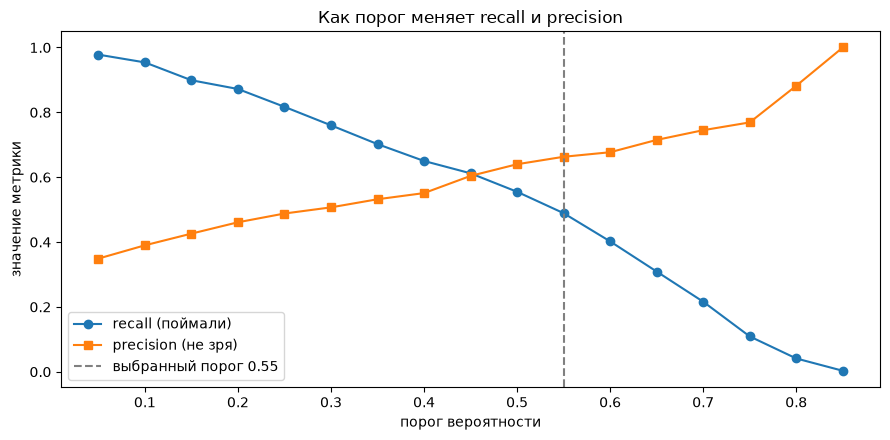

In [12]:
# картинка для защиты: как порог меняет охват и точность
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(thr_df["порог"], thr_df["recall"], marker="o", label="recall (поймали)")
ax.plot(thr_df["порог"], thr_df["precision"], marker="s", label="precision (не зря)")
ax.axvline(best["порог"], color="gray", linestyle="--",
           label=f"выбранный порог {best['порог']}")
ax.set_xlabel("порог вероятности")
ax.set_ylabel("значение метрики")
ax.set_title("Как порог меняет recall и precision")
ax.legend()
plt.tight_layout()
plt.savefig(FIG / "pz3.png", dpi=160, bbox_inches="tight")
plt.show()

# Вывод: с ростом порога растёт precision и падает recall; выбранный порог —
# компромисс под бюджет 20% базы.


## Итог: заполните карточку

Перенесите в «ПЗ3_Задача_3.docx»:

1. Пять вопросов постановки и типа задачи.
2. Метрику, порог и почему метрика — прокси бизнес-цели.
3. Данные и сплит: дубликаты, пропуски, тип сплита, размеры частей.
4. Базлайн и модель: таблицу метрик.
5. Сравнение и вердикт: достигнут ли порог, насколько лучше базлайна,
   нужен ли ML.
6. Журнал экспериментов: минимум три строки.

**Перед сдачей:** имя файла `ПЗ3_Задача_3.docx`, доступ «Читатель»,
ссылка в таблице команд.
